# DaT Parkinson's Challenge — Starter Notebook

Starter script for the [DaT Parkinson's Challenge](https://www.drivendata.org/competitions/311/dat-parkinsons-challenge/) (DrivenData).

**Before running:** attach the competition's `train_labels.csv` + `niftis/*.nii.gz` files as a Kaggle Dataset via **Add Input** in the right sidebar (dataset must be downloaded from DrivenData's own data page and uploaded manually — see project notes).

What this notebook does:
1. Lists attached input files
2. Loads `train_labels.csv` and auto-detects the data directory
3. Defines helpers to load a `.nii.gz` volume and plot a grid of axial slices
4. Displays sample normal + abnormal scans side by side

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INPUT_DIR = "/kaggle/input"

print("Attached input datasets/competitions:")
for name in sorted(os.listdir(INPUT_DIR)):
    print(" -", name)

n_printed = 0
for dirname, _, filenames in os.walk(INPUT_DIR):
    for filename in filenames:
        print(os.path.join(dirname, filename))
        n_printed += 1
        if n_printed >= 20:
            break
    if n_printed >= 20:
        break

Attached input datasets/competitions:
 - datasets
/kaggle/input/datasets/harshdipsaha/dat-parkinsons-challenge-data/train_labels_JNDlMjr.csv
/kaggle/input/datasets/harshdipsaha/dat-parkinsons-challenge-data/niftis_utCGpHE/huxg2myr.nii
/kaggle/input/datasets/harshdipsaha/dat-parkinsons-challenge-data/niftis_utCGpHE/zhdv5ojz.nii
/kaggle/input/datasets/harshdipsaha/dat-parkinsons-challenge-data/niftis_utCGpHE/jgzlma5u.nii
/kaggle/input/datasets/harshdipsaha/dat-parkinsons-challenge-data/niftis_utCGpHE/asifpwio.nii
/kaggle/input/datasets/harshdipsaha/dat-parkinsons-challenge-data/niftis_utCGpHE/e088o98b.nii
/kaggle/input/datasets/harshdipsaha/dat-parkinsons-challenge-data/niftis_utCGpHE/eqe5158o.nii
/kaggle/input/datasets/harshdipsaha/dat-parkinsons-challenge-data/niftis_utCGpHE/pwbsf3q0.nii
/kaggle/input/datasets/harshdipsaha/dat-parkinsons-challenge-data/niftis_utCGpHE/h2m5zja8.nii
/kaggle/input/datasets/harshdipsaha/dat-parkinsons-challenge-data/niftis_utCGpHE/5m8kb9w4.nii
/kaggle/input

In [2]:
# --- DrivenData "Data download" page contents (for reference) ---
# niftis.zip           Training set of DaT scans in NIfTI format.
# train_labels.csv     Labels for training set of DaT scans.
# smoke_test_data.tar.gz
#     Contains materials to check that your submission works as expected
#     using the runtime repo: 20 sample images (from the training set) in
#     a niftis/ folder, plus submission_format.csv and test_labels.csv at
#     the root. Unpack into data-demo/ in the runtime repo to run
#     'just test-submission' locally. Not needed for this EDA/training
#     notebook -- only train_labels.csv + the niftis are used below.
#
# Uploaded here as a private Kaggle Dataset: dat-parkinsons-challenge-data.
# Kaggle nests attached data under /kaggle/input/datasets/<owner>/<slug>/,
# auto-extracts uploaded archives (niftis.zip -> a folder of files),
# auto-decompresses each .nii.gz into plain .nii, and can rename files
# (a random suffix gets added if the local download had a name clash) --
# so we discover everything below by walking /kaggle/input rather than
# hardcoding paths.

import nibabel as nib


def _find_labels_csv(root):
    for dirpath, _, filenames in os.walk(root):
        for fn in filenames:
            if not fn.lower().endswith(".csv"):
                continue
            path = os.path.join(dirpath, fn)
            try:
                df = pd.read_csv(path, nrows=5)
            except Exception:
                continue
            if "uid" in df.columns and "is_pathologic" in df.columns:
                return path
    return None


def _find_niftis_dir(root):
    best_dir, best_count = None, 0
    for dirpath, _, filenames in os.walk(root):
        count = sum(1 for fn in filenames if fn.endswith(".nii") or fn.endswith(".nii.gz"))
        if count > best_count:
            best_dir, best_count = dirpath, count
    return best_dir


labels_path = _find_labels_csv(INPUT_DIR)
if labels_path is None:
    print("No DaT Parkinson's data found under /kaggle/input yet.")
    print("Attach the dataset via 'Add Input' in the right sidebar, then re-run this cell.")
    DATA_DIR = None
    labels = None
    niftis_dir = None
else:
    DATA_DIR = os.path.dirname(labels_path)
    print("Found labels csv at:", labels_path)
    labels = pd.read_csv(labels_path)
    print("train_labels shape:", labels.shape)
    display(labels.head())
    print(labels["is_pathologic"].value_counts())

    niftis_dir = _find_niftis_dir(DATA_DIR)
    print("Using niftis directory:", niftis_dir)

Found labels csv at: /kaggle/input/datasets/harshdipsaha/dat-parkinsons-challenge-data/train_labels_JNDlMjr.csv
train_labels shape: (1362, 2)


,uid,is_pathologic
0,xaji0y6d,0.0
1,pbhsahxt,0.0
2,hv3a3zmf,0.0
3,8mdd4v30,0.0
4,t9nt3w5u,1.0


is_pathologic
1.0    747
0.0    615
Name: count, dtype: int64
Using niftis directory: /kaggle/input/datasets/harshdipsaha/dat-parkinsons-challenge-data/niftis_utCGpHE


In [3]:
def load_volume(uid, niftis_dir=niftis_dir):
    """Load a DaT scan NIfTI volume by uid. Returns (numpy array, voxel spacing)."""
    for ext in (".nii.gz", ".nii"):
        path = os.path.join(niftis_dir, f"{uid}{ext}")
        if os.path.exists(path):
            img = nib.load(path)
            return img.get_fdata(), img.header.get_zooms()
    raise FileNotFoundError(f"No NIfTI file found for uid={uid} in {niftis_dir}")


def show_axial_grid(vol, uid="", label=None, n_slices=9, cmap="hot"):
    """Plot a grid of evenly spaced axial slices through the striatum region."""
    z_dim = vol.shape[2]
    z_start, z_end = int(z_dim * 0.35), int(z_dim * 0.65)
    idxs = np.linspace(z_start, z_end, n_slices).astype(int)

    fig, axes = plt.subplots(3, 3, figsize=(9, 9))
    title = f"uid={uid}"
    if label is not None:
        title += "  label=" + ("abnormal" if label == 1 else "normal")
    fig.suptitle(title)
    for ax, z in zip(axes.ravel(), idxs):
        ax.imshow(vol[:, :, z].T, cmap=cmap, origin="lower")
        ax.set_title(f"z={z}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

uid=h3wqa1vr shape=(256, 256, 256) voxel spacing=(np.float32(2.46), np.float32(2.46), np.float32(2.46))


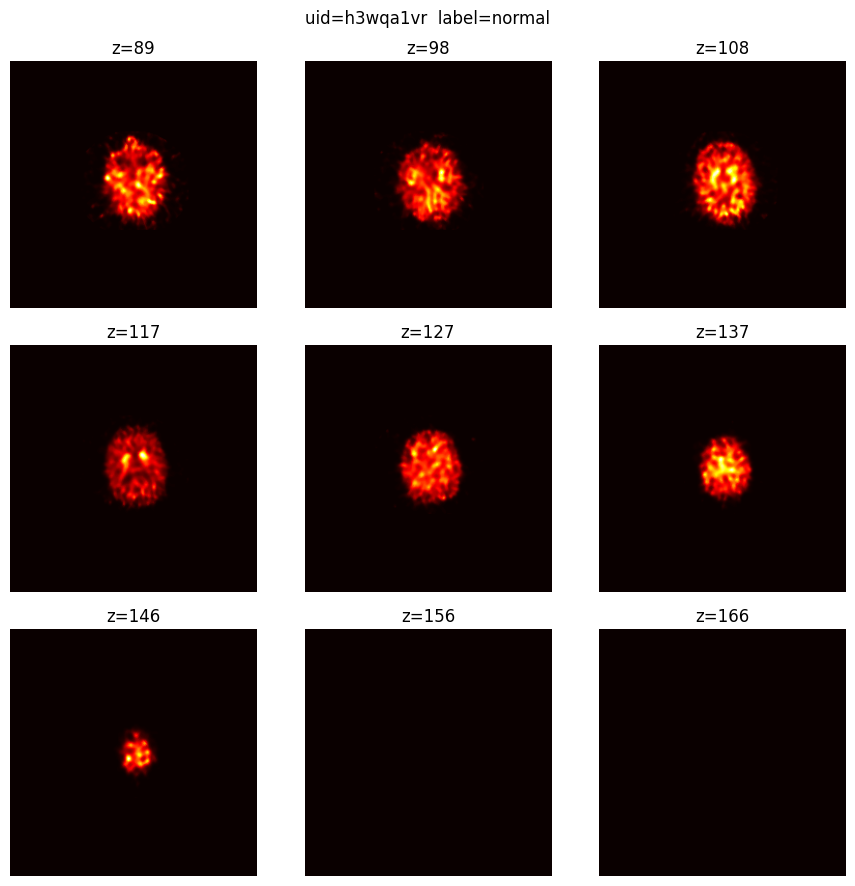

uid=unvsdkv5 shape=(128, 128, 87) voxel spacing=(np.float32(2.3976), np.float32(2.3976), np.float32(2.3976))


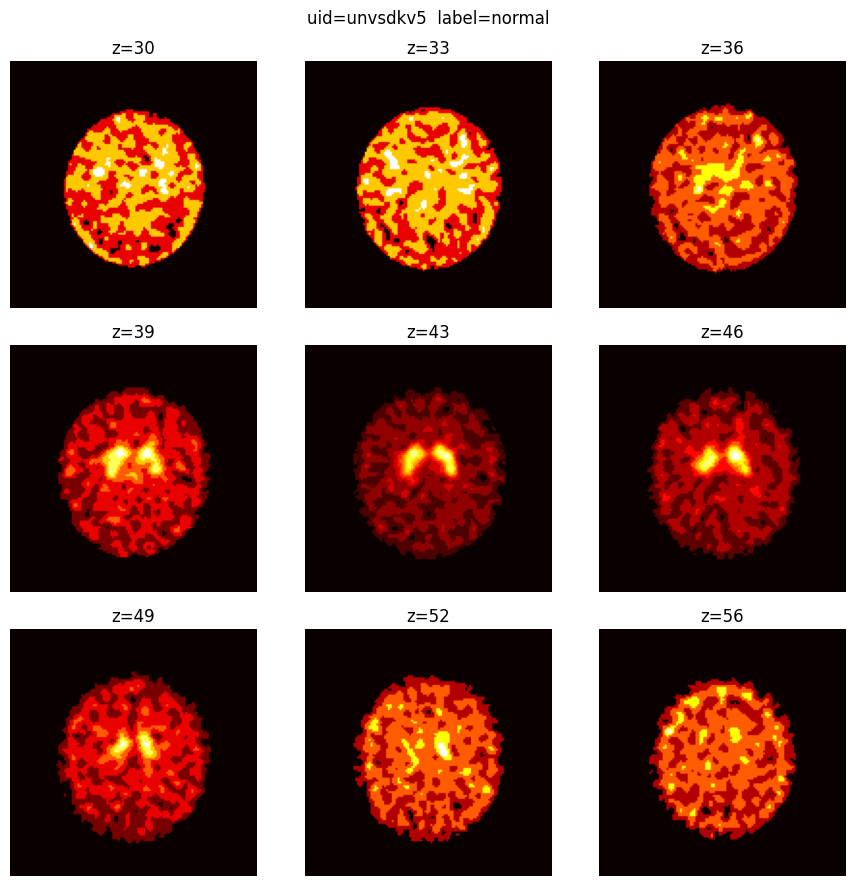

uid=je2ab2rv shape=(256, 256, 256) voxel spacing=(np.float32(2.46), np.float32(2.46), np.float32(2.46))


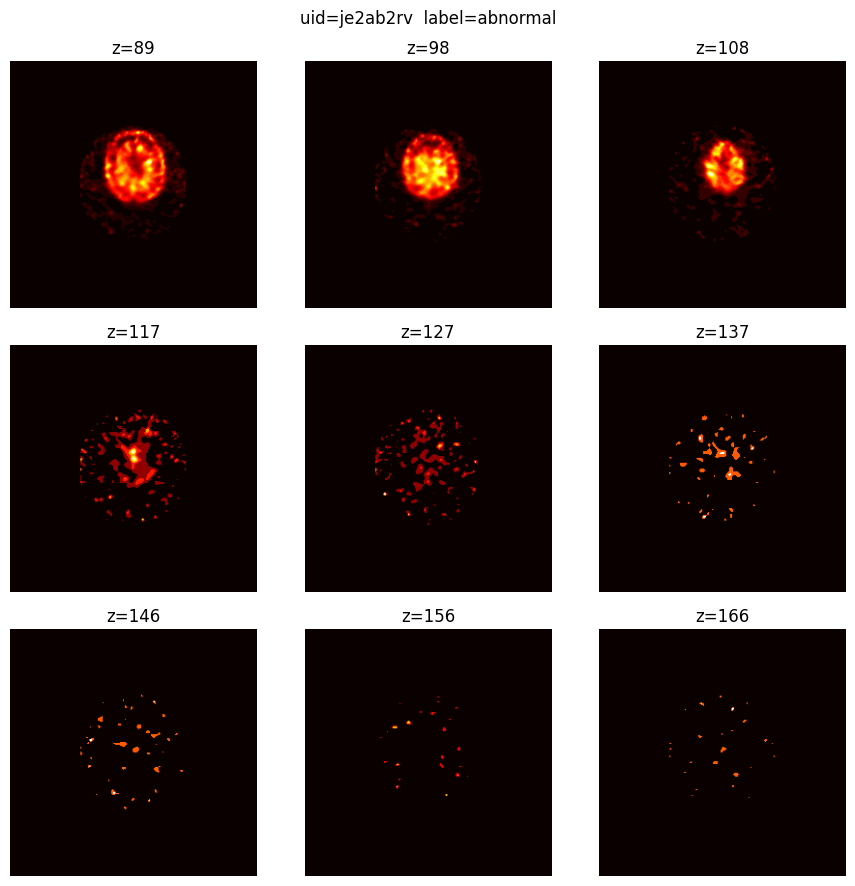

uid=2movs0cd shape=(256, 256, 256) voxel spacing=(np.float32(2.46), np.float32(2.46), np.float32(2.46))


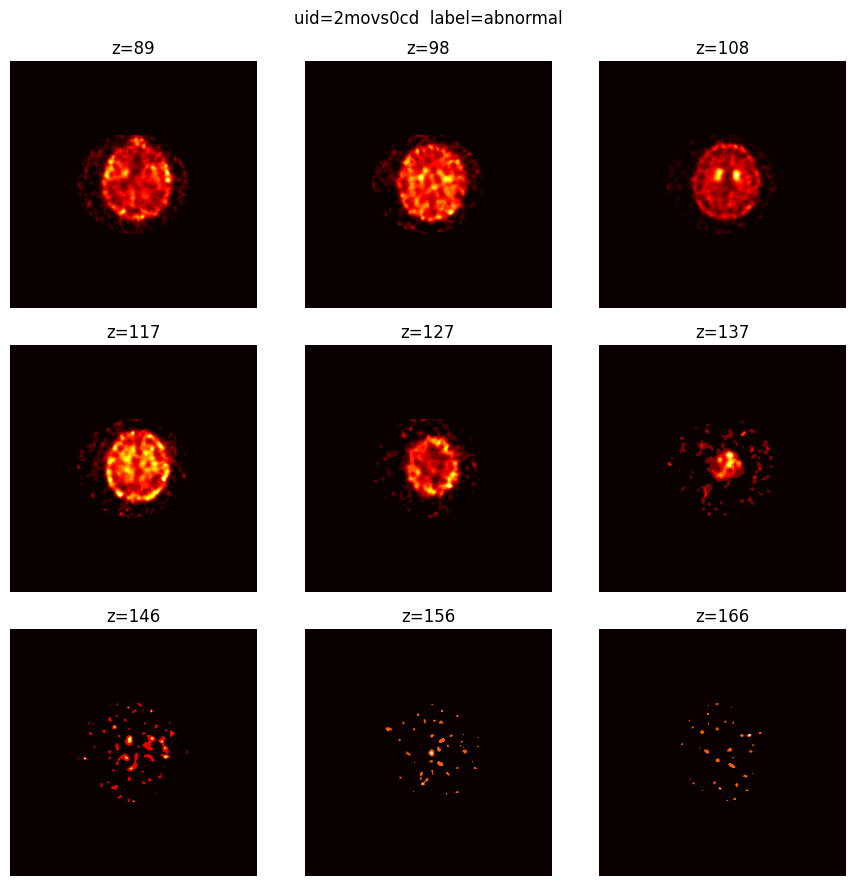

In [4]:
if DATA_DIR is not None and labels is not None:
    rng = np.random.default_rng(0)
    normal_uids = labels.loc[labels["is_pathologic"] == 0, "uid"].tolist()
    abnormal_uids = labels.loc[labels["is_pathologic"] == 1, "uid"].tolist()

    sample_uids = []
    sample_uids += list(rng.choice(normal_uids, size=min(2, len(normal_uids)), replace=False))
    sample_uids += list(rng.choice(abnormal_uids, size=min(2, len(abnormal_uids)), replace=False))

    for uid in sample_uids:
        label = labels.loc[labels["uid"] == uid, "is_pathologic"].iloc[0]
        vol, zooms = load_volume(uid)
        print(f"uid={uid} shape={vol.shape} voxel spacing={zooms}")
        show_axial_grid(vol, uid=uid, label=label)
else:
    print("Attach the dataset (see cell above) to run sample visualization.")

## Detailed Exploratory Data Analysis

Goal: characterize class balance, volume geometry (shape/spacing) across the
10 contributing hospitals, check for scanner/center-driven label imbalance
(a domain-shift/shortcut risk), look at raw intensity statistics, and test
a single naive hand-crafted "uptake ratio" feature to get a first read on
how much signal is recoverable without deep learning.

In [5]:
import time

def find_file(uid, niftis_dir=niftis_dir):
    for ext in (".nii.gz", ".nii"):
        p = os.path.join(niftis_dir, f"{uid}{ext}")
        if os.path.exists(p):
            return p
    return None

records = []
t0 = time.time()
for i, row in labels.iterrows():
    uid = row["uid"]
    path = find_file(uid)
    if path is None:
        records.append({"uid": uid, "is_pathologic": row["is_pathologic"], "file_found": False})
        continue
    img = nib.load(path)
    shape = img.shape
    zooms = img.header.get_zooms()
    records.append({
        "uid": uid,
        "is_pathologic": row["is_pathologic"],
        "file_found": True,
        "dtype": str(img.get_data_dtype()),
        "shape_x": shape[0], "shape_y": shape[1], "shape_z": shape[2],
        "spacing_x": float(zooms[0]), "spacing_y": float(zooms[1]), "spacing_z": float(zooms[2]),
        "file_size_mb": os.path.getsize(path) / 1e6,
    })
    if (i + 1) % 200 == 0:
        print(f"  processed {i + 1}/{len(labels)} headers...")

meta_df = pd.DataFrame(records)
print(f"Header scan done in {time.time() - t0:.1f}s")
print("Files found:", meta_df["file_found"].sum(), "/", len(meta_df))
missing = meta_df[~meta_df["file_found"]]
if len(missing):
    print("WARNING: missing files for", len(missing), "uids")
    display(missing.head())
meta_df.head()

  processed 200/1362 headers...
  processed 400/1362 headers...
  processed 600/1362 headers...
  processed 800/1362 headers...
  processed 1000/1362 headers...
  processed 1200/1362 headers...
Header scan done in 16.6s
Files found: 1362 / 1362


,uid,is_pathologic,file_found,dtype,shape_x,shape_y,shape_z,spacing_x,spacing_y,spacing_z,file_size_mb
0,xaji0y6d,0.0,True,uint16,142,142,112,2.46,2.46,2.46,4.517088
1,pbhsahxt,0.0,True,uint16,142,142,112,2.46,2.46,2.46,4.517088
2,hv3a3zmf,0.0,True,uint16,148,148,112,2.46,2.46,2.46,4.906848
3,8mdd4v30,0.0,True,uint16,164,164,112,2.46,2.46,2.46,6.025056
4,t9nt3w5u,1.0,True,uint16,156,156,112,2.46,2.46,2.46,5.451616


Class balance:
  Normal (0.0): 615 (45.2%)
  Abnormal (1.0): 747 (54.8%)
Imbalance ratio (majority/minority): 1.21:1


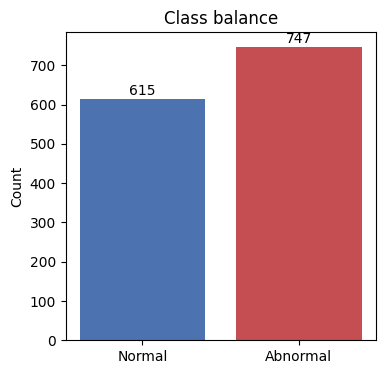


Duplicate uids in train_labels.csv: 0
Missing labels: 0


In [6]:
counts = labels["is_pathologic"].value_counts().sort_index()
pct = (counts / counts.sum() * 100).round(1)
print("Class balance:")
for k in counts.index:
    label_name = "Normal (0.0)" if k == 0 else "Abnormal (1.0)"
    print(f"  {label_name}: {counts[k]} ({pct[k]}%)")
print(f"Imbalance ratio (majority/minority): {counts.max() / counts.min():.2f}:1")

fig, ax = plt.subplots(figsize=(4, 4))
ax.bar(["Normal", "Abnormal"], counts.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 10, str(v), ha="center")
ax.set_ylabel("Count")
ax.set_title("Class balance")
plt.show()

print("\nDuplicate uids in train_labels.csv:", labels["uid"].duplicated().sum())
print("Missing labels:", labels["is_pathologic"].isna().sum())

Volume shape summary:


,shape_x,shape_y,shape_z
count,1362.000000,1362.000000,1362.000000
mean,171.944200,171.944200,142.712922
std,60.195883,60.195883,86.338477
min,118.000000,118.000000,33.000000
25%,128.000000,128.000000,55.000000
50%,128.000000,128.000000,128.000000
75%,256.000000,256.000000,256.000000
max,256.000000,256.000000,256.000000



Top 15 most common (shape_x, shape_y, shape_z) combinations:


shape_x  shape_y  shape_z
256      256      256        460
128      128      128        295
                  87         143
                  45          46
                  43          38
                  39          33
                  40          29
                  42          28
                  90          26
                  41          26
                  38          25
                  49          21
                  37          19
                  36          16
                  44          12
dtype: int64

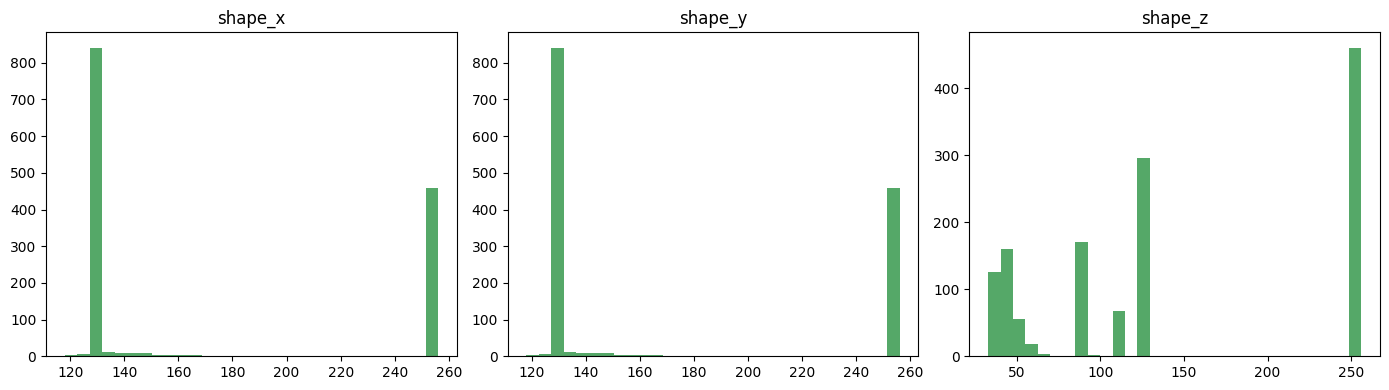

In [7]:
found = meta_df[meta_df["file_found"]].copy()

print("Volume shape summary:")
display(found[["shape_x", "shape_y", "shape_z"]].describe())

print("\nTop 15 most common (shape_x, shape_y, shape_z) combinations:")
shape_counts = found.groupby(["shape_x", "shape_y", "shape_z"]).size().sort_values(ascending=False)
display(shape_counts.head(15))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["shape_x", "shape_y", "shape_z"]):
    ax.hist(found[col], bins=30, color="#55A868")
    ax.set_title(col)
plt.tight_layout()
plt.show()

Unique (rounded) voxel spacings and counts:


spacing_x_rounded
2.460    528
3.895    325
2.300    207
2.398    149
3.296     26
1.468     25
3.305     13
2.000     10
3.591      9
4.420      9
1.654      5
1.578      3
1.619      3
1.640      3
1.530      2
1.537      2
1.455      2
1.626      2
1.592      2
1.756      2
1.523      2
1.503      2
1.633      2
1.605      2
1.688      2
1.544      1
1.461      1
1.482      1
1.564      1
1.585      1
1.571      1
1.509      1
1.612      1
1.372      1
1.750      1
2.415      1
2.129      1
1.743      1
1.708      1
1.496      1
1.674      1
1.413      1
1.599      1
2.127      1
2.017      1
1.882      1
2.360      1
1.647      1
1.715      1
1.695      1
Name: count, dtype: int64

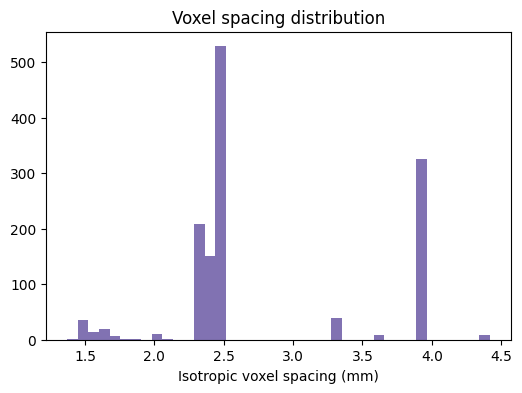

In [8]:
found["spacing_x_rounded"] = found["spacing_x"].round(3)

print("Unique (rounded) voxel spacings and counts:")
spacing_counts = found["spacing_x_rounded"].value_counts().sort_values(ascending=False)
display(spacing_counts)

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(found["spacing_x"], bins=40, color="#8172B2")
ax.set_xlabel("Isotropic voxel spacing (mm)")
ax.set_title("Voxel spacing distribution")
plt.show()

,Normal,Abnormal,Total,% Abnormal
spacing_cluster,,,,
2.46,213,315,528,59.7
3.90,136,189,325,58.2
2.30,103,104,207,50.2
2.40,80,69,149,46.3
3.30,18,21,39,53.8
1.47,14,11,25,44.0
2.00,3,7,10,70.0
4.42,2,7,9,77.8
3.59,6,3,9,33.3


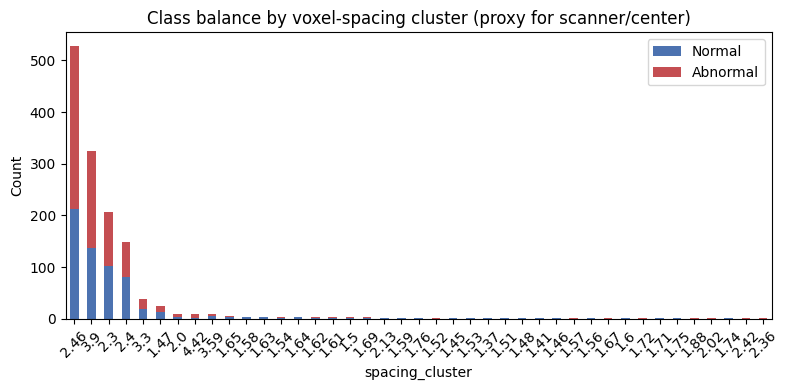

In [9]:
# Bucket spacing into clusters (rounding absorbs floating point noise per scanner)
found["spacing_cluster"] = found["spacing_x"].round(2)

ct = pd.crosstab(found["spacing_cluster"], found["is_pathologic"])
ct.columns = ["Normal", "Abnormal"]
ct["Total"] = ct.sum(axis=1)
ct["% Abnormal"] = (ct["Abnormal"] / ct["Total"] * 100).round(1)
ct = ct.sort_values("Total", ascending=False)
display(ct)

fig, ax = plt.subplots(figsize=(8, 4))
ct[["Normal", "Abnormal"]].plot(kind="bar", stacked=True, ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_ylabel("Count")
ax.set_title("Class balance by voxel-spacing cluster (proxy for scanner/center)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
def crude_uptake_ratio(vol):
    """Naive hand-crafted proxy: peak central (striatal-ish) signal vs background ring."""
    z_dim = vol.shape[2]
    z_lo, z_hi = int(z_dim * 0.40), int(z_dim * 0.60)
    slab_mean = vol[:, :, z_lo:z_hi].mean(axis=2)
    x_dim, y_dim = slab_mean.shape
    cx, cy = x_dim / 2, y_dim / 2
    yy, xx = np.mgrid[0:x_dim, 0:y_dim]
    dist = np.sqrt((xx - cx) ** 2 + (yy - cy) ** 2)
    r = min(x_dim, y_dim)
    central_mask = dist <= r * 0.18
    bg_mask = (dist > r * 0.25) & (dist <= r * 0.45)
    central_peak = np.percentile(slab_mean[central_mask], 95) if central_mask.any() else np.nan
    bg_mean = slab_mean[bg_mask].mean() if bg_mask.any() else np.nan
    return central_peak / (bg_mean + 1e-6)


SAMPLE_N = 500
sample_labels = labels.sample(n=min(SAMPLE_N, len(labels)), random_state=0).reset_index(drop=True)

sample_records = []
t0 = time.time()
for i, row in sample_labels.iterrows():
    uid = row["uid"]
    path = find_file(uid)
    if path is None:
        continue
    vol = nib.load(path).get_fdata()
    sample_records.append({
        "uid": uid,
        "is_pathologic": row["is_pathologic"],
        "intensity_min": float(vol.min()),
        "intensity_max": float(vol.max()),
        "intensity_mean": float(vol.mean()),
        "intensity_std": float(vol.std()),
        "uptake_ratio": crude_uptake_ratio(vol),
    })
    if (i + 1) % 100 == 0:
        print(f"  processed {i + 1}/{len(sample_labels)} volumes ({time.time() - t0:.0f}s elapsed)...")

sample_df = pd.DataFrame(sample_records)
print(f"\nDone. {len(sample_df)} volumes processed in {time.time() - t0:.0f}s")
sample_df.head()

  processed 100/500 volumes (20s elapsed)...
  processed 200/500 volumes (37s elapsed)...
  processed 300/500 volumes (56s elapsed)...
  processed 400/500 volumes (71s elapsed)...
  processed 500/500 volumes (90s elapsed)...

Done. 500 volumes processed in 90s


,uid,is_pathologic,intensity_min,intensity_max,intensity_mean,intensity_std,uptake_ratio
0,auxbgk2w,1.0,0.0,56.0,0.120020,0.960614,3.960784e+06
1,mpryfzmy,0.0,0.0,11.0,0.316570,0.871799,1.803371e+01
2,r6yo6z1t,1.0,0.0,57.0,1.781664,3.721988,1.165950e+01
3,t1ghr09s,0.0,0.0,7729.0,48.157414,222.334759,8.699082e+01
4,jwtektsg,1.0,0.0,60579.0,2760.906961,5417.813831,1.422576e+01


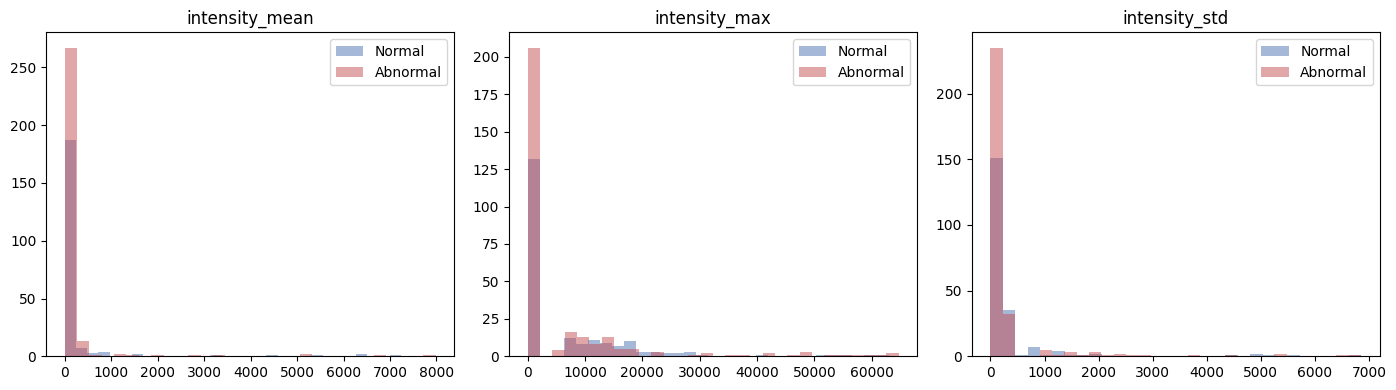

is_pathologic                  0.0           1.0
intensity_mean count    209.000000    291.000000
               mean     225.648353    152.728133
               std      966.328187    797.805108
               min        0.107768      0.073446
               25%        2.107597      0.320580
               50%        7.322778      3.321945
               75%       27.183665     20.468792
               max     7237.940773   7981.866102
intensity_max  count    209.000000    291.000000
               mean    6674.971292   5707.123711
               std    11297.042969  12244.497845
               min        7.000000      5.000000
               25%       88.000000     60.500000
               50%      255.000000    117.000000
               75%    11543.000000   7820.000000
               max    62908.000000  64650.000000
intensity_std  count    209.000000    291.000000
               mean     314.744115    271.122083
               std      930.462162    874.868059
               min        0.557674      0.421994
               25%        4.210516      1.369592
               50%       15.194741      7.143852
               75%      238.355069    171.588495
               max     6860.647632   6843.543016

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["intensity_mean", "intensity_max", "intensity_std"]):
    for label_val, name, color in [(0.0, "Normal", "#4C72B0"), (1.0, "Abnormal", "#C44E52")]:
        vals = sample_df.loc[sample_df["is_pathologic"] == label_val, col]
        ax.hist(vals, bins=30, alpha=0.5, label=name, color=color)
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

display(sample_df.groupby("is_pathologic")[["intensity_mean", "intensity_max", "intensity_std"]].describe().T)

/tmp/ipykernel_16/3596334037.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_to_plot, labels=["Normal", "Abnormal"])


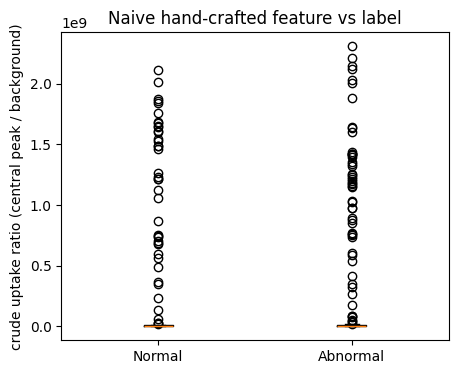

AUROC of single crude 'uptake ratio' feature vs label: 0.469  (n=500)


In [12]:
from sklearn.metrics import roc_auc_score

fig, ax = plt.subplots(figsize=(5, 4))
data_to_plot = [
    sample_df.loc[sample_df["is_pathologic"] == 0, "uptake_ratio"].dropna(),
    sample_df.loc[sample_df["is_pathologic"] == 1, "uptake_ratio"].dropna(),
]
ax.boxplot(data_to_plot, labels=["Normal", "Abnormal"])
ax.set_ylabel("crude uptake ratio (central peak / background)")
ax.set_title("Naive hand-crafted feature vs label")
plt.show()

valid = sample_df.dropna(subset=["uptake_ratio"])
# lower ratio is expected for abnormal (reduced uptake), so negate for AUC's "higher score = positive class" convention
auc = roc_auc_score(valid["is_pathologic"], -valid["uptake_ratio"])
print(f"AUROC of single crude 'uptake ratio' feature vs label: {auc:.3f}  (n={len(valid)})")

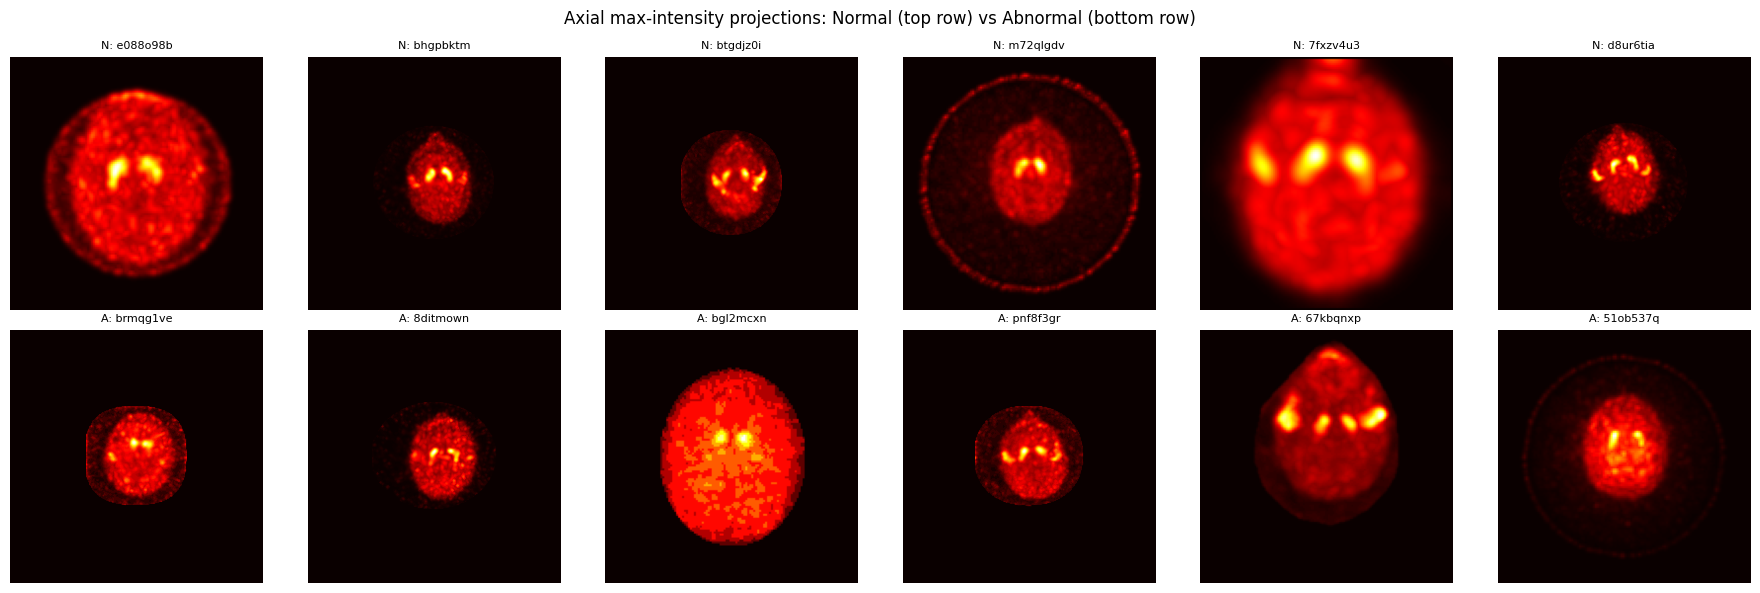

In [13]:
def mip_2d(vol, axis=2):
    return vol.max(axis=axis)

n_each = 6
normal_sample = sample_df[sample_df["is_pathologic"] == 0].sample(n_each, random_state=1)["uid"].tolist()
abnormal_sample = sample_df[sample_df["is_pathologic"] == 1].sample(n_each, random_state=1)["uid"].tolist()

fig, axes = plt.subplots(2, n_each, figsize=(3 * n_each, 6))
for ax, uid in zip(axes[0], normal_sample):
    vol, _ = load_volume(uid)
    ax.imshow(mip_2d(vol).T, cmap="hot", origin="lower")
    ax.set_title(f"N: {uid}", fontsize=8)
    ax.axis("off")
for ax, uid in zip(axes[1], abnormal_sample):
    vol, _ = load_volume(uid)
    ax.imshow(mip_2d(vol).T, cmap="hot", origin="lower")
    ax.set_title(f"A: {uid}", fontsize=8)
    ax.axis("off")

plt.suptitle("Axial max-intensity projections: Normal (top row) vs Abnormal (bottom row)")
plt.tight_layout()
plt.show()

## Key findings & recommended approach

**Class balance** — 1,362 training exams: 747 abnormal (54.8%) / 615 normal
(45.2%), imbalance ratio only **1.21:1**. No duplicate uids, no missing
labels. This is mild — standard log-loss training + stratified CV is
enough; no need for heavy class-weighting or resampling.

**Volume geometry is genuinely heterogeneous** — two dominant shape
clusters, 256×256×256 (460 scans, ~34%) and 128×128×{25–128 slices}
(~another third), plus a long tail down to 33 slices (shape_z std = 86!).
Voxel spacing clusters around 2.46mm (~39%), 3.90mm (~24%), 2.30mm (~15%),
2.40mm (~11%), plus 30+ unique small clusters (<10 scans each) —
consistent with 10 different hospitals/scanners. **A fixed input
shape/spacing assumption will break** — resampling to a common isotropic
spacing (+ crop/pad or registration to a template) is mandatory
preprocessing, not optional.

**No major scanner-driven label shortcut** — for the 4 dominant spacing
clusters (~89% of the data), % abnormal ranges 46–60%, close to the 54.8%
baseline. The long tail of tiny spacing clusters shows 0%/100% abnormal,
but that's small-sample noise (n<10), not a reliable leak — still worth
a spacing/hospital-aware CV split to get an honest generalization read.

**Intensity scale is NOT consistent across the dataset** — sampled 500
volumes: intensity_max is strongly bimodal, many volumes cap near 255
(8-bit-like) while others range up to ~65,000 (raw SPECT counts). **Per-
volume intensity normalization (percentile clip + rescale, or z-score) is
essential** before any model sees this data, or it will just learn the
scale artifact.

**A naive hand-crafted feature found ~zero signal** — a crude
"central-peak / background-ring" uptake-ratio proxy (unregistered, fixed
relative-position ROI) scored **AUROC = 0.469** — indistinguishable from
chance. The raw max-intensity-projection visual grid (6 normal vs 6
abnormal) also didn't show an obvious, consistent visual separation to
the eye. This means the heterogeneity in shape/spacing/orientation is
likely washing out the real diagnostic pattern until volumes are properly
spatially normalized — consistent with the literature review finding
that essentially every published high-accuracy result first registers
scans to a common template (e.g. MNI space) before extracting features.

### Recommended approach
1. **Registration/resampling is the top engineering priority**, ahead of
   model choice: resample every volume to a common isotropic spacing and
   align to a common frame (at minimum center-of-mass + isotropic
   resample; ideally affine registration to a template) before any
   feature extraction or training.
2. **Per-volume intensity normalization** (e.g. clip to [p1, p99] then
   rescale to [0, 1]) is mandatory given the raw-count-vs-8-bit scale
   mismatch found above.
3. Class imbalance is mild — don't over-engineer for it; focus effort on
   preprocessing instead.
4. Given the literature finding that classical radiomics matched deep
   learning on properly-registered PPMI data, it's worth re-testing a
   hand-crafted striatal-ratio feature *after* proper registration — our
   AUROC=0.469 result here reflects a bad ROI heuristic, not necessarily
   an absence of signal.
5. Use a spacing/hospital-aware stratified k-fold for cross-validation
   to get an honest estimate of cross-center generalization, matching the
   real (multi-center) held-out test set.

## Additional checks (per a generic scientific-data EDA checklist)

The following extends the EDA above with a few checks a general
file-format-aware EDA methodology calls out that we hadn't covered yet:
tabular data-quality checks (dtypes, id format, label domain) and
imaging-specific header metadata (bit depth/dtype consistency across
**all** volumes, dimensionality sanity check, orientation codes, and
intensity-scaling factors) — the latter directly tests the "intensity
scale is inconsistent" finding above against the NIfTI header itself.

In [14]:
# --- Tabular (train_labels.csv) data-quality checks ---
print("labels.dtypes:")
print(labels.dtypes)
print()
print("uid length distribution:", labels["uid"].str.len().value_counts().to_dict())
print("uid charset check (all lowercase alnum?):",
      bool(labels["uid"].str.match(r"^[a-z0-9]+$").all()))
print("is_pathologic unique values:", sorted(labels["is_pathologic"].unique().tolist()))

labels.dtypes:
uid               object
is_pathologic    float64
dtype: object

uid length distribution: {8: 1362}
uid charset check (all lowercase alnum?): True
is_pathologic unique values: [0.0, 1.0]


In [15]:
# --- Imaging (NIfTI) header metadata: dtype / dimensionality / orientation / scaling ---
extra_records = []
t0 = time.time()
for i, row in labels.iterrows():
    uid = row["uid"]
    path = find_file(uid)
    if path is None:
        continue
    img = nib.load(path)
    hdr = img.header
    slope = float(hdr["scl_slope"])
    inter = float(hdr["scl_inter"])
    extra_records.append({
        "uid": uid,
        "ndim": len(img.shape),
        "dtype": str(img.get_data_dtype()),
        "qform_code": int(hdr["qform_code"]),
        "sform_code": int(hdr["sform_code"]),
        "scl_slope": None if np.isnan(slope) else slope,
        "scl_inter": None if np.isnan(inter) else inter,
        "cal_min": float(hdr["cal_min"]),
        "cal_max": float(hdr["cal_max"]),
    })
    if (i + 1) % 400 == 0:
        print(f"  processed {i + 1}/{len(labels)}...")

extra_df = pd.DataFrame(extra_records)
print(f"Done in {time.time() - t0:.1f}s\n")

print("ndim value counts:")
print(extra_df["ndim"].value_counts())
print("\ndtype value counts:")
print(extra_df["dtype"].value_counts())
print("\nqform_code value counts:")
print(extra_df["qform_code"].value_counts())
print("\nsform_code value counts:")
print(extra_df["sform_code"].value_counts())
print("\nscl_slope value counts (top 10, incl. missing):")
print(extra_df["scl_slope"].value_counts(dropna=False).head(10))
print("\nscl_inter value counts (top 10, incl. missing):")
print(extra_df["scl_inter"].value_counts(dropna=False).head(10))
print("\ncal_min / cal_max summary:")
display(extra_df[["cal_min", "cal_max"]].describe())

  processed 400/1362...
  processed 800/1362...
  processed 1200/1362...
Done in 6.6s

ndim value counts:
ndim
3    1362
Name: count, dtype: int64

dtype value counts:
dtype
uint16    1346
int16       16
Name: count, dtype: int64

qform_code value counts:
qform_code
1    1362
Name: count, dtype: int64

sform_code value counts:
sform_code
1    1362
Name: count, dtype: int64

scl_slope value counts (top 10, incl. missing):
scl_slope
None    1362
Name: count, dtype: int64

scl_inter value counts (top 10, incl. missing):
scl_inter
None    1362
Name: count, dtype: int64

cal_min / cal_max summary:


,cal_min,cal_max
count,1362.0,1362.0
mean,0.0,0.0
std,0.0,0.0
min,0.0,0.0
25%,0.0,0.0
50%,0.0,0.0
75%,0.0,0.0
max,0.0,0.0


In [16]:
# Does dtype/scl_slope explain the earlier "255 vs ~65000" intensity_max bimodality?
joined = sample_df.merge(extra_df, on="uid", how="left")
joined["scale_regime"] = np.where(joined["intensity_max"] <= 1000, "low (<=1000)", "high (>1000)")

print("dtype vs scale_regime:")
display(pd.crosstab(joined["scale_regime"], joined["dtype"]))

print("\nscl_slope by scale_regime:")
display(joined.groupby("scale_regime")["scl_slope"].describe())

print("\nscl_inter by scale_regime:")
display(joined.groupby("scale_regime")["scl_inter"].describe())

dtype vs scale_regime:


dtype,int16,uint16
scale_regime,,
high (>1000),2,165
low (<=1000),4,329



scl_slope by scale_regime:


,count,unique,top,freq
scale_regime,,,,
high (>1000),0,0,NaN,NaN
low (<=1000),0,0,NaN,NaN



scl_inter by scale_regime:


,count,unique,top,freq
scale_regime,,,,
high (>1000),0,0,NaN,NaN
low (<=1000),0,0,NaN,NaN


### Refinement from the header-metadata checks

- **Tabular data is clean**: all uids are 8-char lowercase alphanumeric,
  `is_pathologic` only ever takes {0.0, 1.0} — no coercion issues to
  worry about.
- **All 1,362 volumes are genuinely 3D** (no stray 4D scans), and
  **qform_code / sform_code are both = 1 for every volume** — i.e. every
  center encoded spatial orientation the same consistent way, which is
  good news for building a registration pipeline (no header-convention
  surprises to handle per-center).
- **dtype is overwhelmingly consistent** (1,346 uint16 / 16 int16) and
  does **not** correlate with the earlier "low vs high intensity_max"
  split (both dtypes appear in both regimes) — so the bimodal intensity
  scale is *not* a storage-format artifact.
- **scl_slope / scl_inter / cal_min / cal_max are unset for every single
  volume** — meaning there is no header field we could read to
  auto-correct the intensity scale mismatch found earlier. This confirms
  the bimodal "255 vs ~65,000" split reflects a genuine difference in how
  each site's reconstruction software quantized counts, not a decodable
  scaling factor — **per-volume percentile-based normalization remains
  the correct fix**, not a header-metadata lookup.

## Further additions (per the K-Dense "exploratory-data-analysis" scientific-agent skill)

That skill's methodology emphasizes a few things we hadn't done yet:
a **missingness/leakage audit** (here: metadata-signature duplicate
detection — a proxy for detecting accidentally-duplicated or repeat-scan
entries), comparing **robust statistics (median/MAD/IQR) against
classical mean/SD** rather than trusting mean/SD alone on skewed data,
a **log-transform sensitivity check**, a **degenerate/blank-scan
integrity check**, and recording **library versions for provenance**.

In [17]:
# --- Metadata-signature duplicate/leakage audit ---
# A cheap, bounded proxy for "does any (uid) share an identical
# shape+spacing+file-size signature with another?" -- a real duplicate or
# repeat-scan entry would show up here without needing to re-read pixel data.
dup_check = (
    found.groupby(["shape_x", "shape_y", "shape_z", "spacing_x", "spacing_y", "spacing_z", "file_size_mb"])
    .agg(n=("uid", "size"), uids=("uid", list))
    .reset_index()
)
dups = dup_check[dup_check["n"] > 1].sort_values("n", ascending=False)
print(f"Found {len(dups)} metadata-signature group(s) shared by >1 volume (out of {len(found)} total).")
if len(dups):
    display(dups[["shape_x", "shape_y", "shape_z", "spacing_x", "spacing_y", "spacing_z", "file_size_mb", "n"]].head(20))
    print("\nExample uid groups (first 5):")
    for uids in dups["uids"].head(5):
        print(" ", uids)
else:
    print("No exact metadata-signature duplicates found across all volumes.")

Found 61 metadata-signature group(s) shared by >1 volume (out of 1362 total).


,shape_x,shape_y,shape_z,spacing_x,spacing_y,spacing_z,file_size_mb,n
133,256,256,256,2.46000,2.46000,2.46000,33.554784,460
110,128,128,128,2.30000,2.30000,2.30000,4.194656,207
100,128,128,87,2.39760,2.39760,2.39760,2.851168,143
112,128,128,128,3.89537,3.89537,3.89537,4.194656,70
15,128,128,43,3.89537,3.89537,3.90000,1.409376,37
9,128,128,39,3.89537,3.89537,3.90000,1.278304,33
10,128,128,40,3.89537,3.89537,3.90000,1.311072,29
13,128,128,42,3.89537,3.89537,3.90000,1.376608,28
12,128,128,41,3.89537,3.89537,3.90000,1.343840,25
8,128,128,38,3.89537,3.89537,3.90000,1.245536,25



Example uid groups (first 5):
  ['ei3zrrhf', '4abufwbu', 'cjg8vuaz', 'xkdq95g3', 'v23gxj0m', 'qvindh4s', 'pfdrwb2s', 'erev361x', 'snbti22n', 'v01zderi', '4k5ogz2u', 'eaxylnfx', 'j4pnjy1o', '2rntjlmz', '04x0qzfh', 'omtzzf8a', 'df7pchcb', 'n9wszv83', 'xphx2kbv', 'sigbiaf9', '2movs0cd', 'k36m8jvh', '7ujodck8', '2853uy8u', '118qqvae', 'cw9yil8s', 'a3idy3c7', 'rm6j8y6r', 'h05hhiwf', 'd7yxw1tb', 'rwr965r9', '6khub2rt', 'soyg9zqy', 'ahulwjti', 'qwnrhzn4', 'kgeuidji', 'pnf8f3gr', '94sz2kuu', 'oyc3rwqm', 'mu7jae58', 'huxg2myr', '06nkwfg3', 'mwu4cfil', 'kjxjq5nv', '8oga0x7z', 'cgdc5tao', '1cjfx5li', 'kwe4bx4l', 'r9tjq8zg', 'vwwusxlm', 't2pnjka3', '4mqa78ra', 'pkianouo', 'f0onjpi1', '63yk03o4', 'gkwwjwga', 'btgdjz0i', 'frml29q2', 'l48c1cqg', '433e1i1p', '0bq1s9ry', 'llwb7sjw', 'h55hewlg', 'je2ab2rv', 'ndfdw79w', 'cxz2ei92', '12pgyme6', 'rpkzggm0', 'j36tcfkj', 'nawnga41', 'izxtnsrt', 'wlxdsc4e', '5hrdu4xs', 'zjnvc7hr', '6c2cu7on', 'z3jbck88', 'd0tgsiwg', '0odwmqx5', 'ggomf9pm', 'l9ln1p0v', 'uh17j

Robust vs classical summary -- intensity_max (raw scale), by label:


,mean,std,median,MAD,IQR
is_pathologic,,,,,
0.0,6674.971292,11297.042969,255.0,210.0,11455.0
1.0,5707.123711,12244.497845,117.0,109.0,7759.5


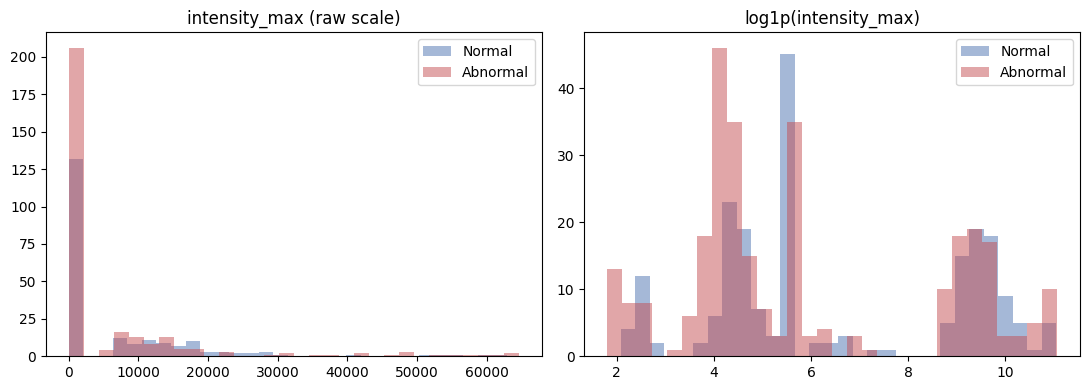

In [18]:
# --- Robust statistics (median/MAD/IQR) vs classical mean/SD, + log-transform sensitivity ---
def robust_summary(s):
    med = s.median()
    mad = (s - med).abs().median()
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({"mean": s.mean(), "std": s.std(), "median": med, "MAD": mad, "IQR": q3 - q1})

print("Robust vs classical summary -- intensity_max (raw scale), by label:")
display(sample_df.groupby("is_pathologic")["intensity_max"].apply(robust_summary).unstack())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label_val, name, color in [(0.0, "Normal", "#4C72B0"), (1.0, "Abnormal", "#C44E52")]:
    vals = sample_df.loc[sample_df["is_pathologic"] == label_val, "intensity_max"]
    axes[0].hist(vals, bins=30, alpha=0.5, label=name, color=color)
    axes[1].hist(np.log1p(vals), bins=30, alpha=0.5, label=name, color=color)
axes[0].set_title("intensity_max (raw scale)")
axes[1].set_title("log1p(intensity_max)")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

In [19]:
# --- Degenerate/blank-scan integrity check ---
degenerate = sample_df[(sample_df["intensity_max"] < 10) | (sample_df["intensity_std"] < 1e-3)]
print(f"Potentially degenerate/blank scans in the 500-volume sample: {len(degenerate)}")
if len(degenerate):
    display(degenerate[["uid", "is_pathologic", "intensity_min", "intensity_max", "intensity_mean", "intensity_std"]])
else:
    print("None found -- no suspiciously blank/near-constant volumes in the sampled set.")

Potentially degenerate/blank scans in the 500-volume sample: 25


,uid,is_pathologic,intensity_min,intensity_max,intensity_mean,intensity_std
14,eq8dh9pt,1.0,0.0,7.0,0.344934,0.861166
17,ryozdppb,1.0,0.0,8.0,0.264177,0.641524
34,v4kfq5dz,1.0,0.0,8.0,0.378873,0.908685
76,6o3z0ani,1.0,0.0,7.0,0.281211,0.705229
98,0j1oulwo,1.0,0.0,6.0,0.239130,0.604604
134,mi6kti22,1.0,0.0,9.0,0.334791,0.869540
135,77jzc58c,1.0,0.0,7.0,0.336286,0.818211
138,68q0j9m4,1.0,0.0,7.0,0.306958,0.708672
141,mz2k1ko6,1.0,0.0,6.0,0.230648,0.585660
161,om2zkf5b,1.0,0.0,5.0,0.169739,0.421994


In [20]:
# --- Provenance: library versions used in this analysis ---
import importlib.metadata as im
for pkg in ["numpy", "pandas", "nibabel", "matplotlib", "scikit-learn"]:
    try:
        print(f"{pkg}: {im.version(pkg)}")
    except im.PackageNotFoundError:
        print(f"{pkg}: not installed")

numpy: 2.0.2
pandas: 2.3.3
nibabel: 5.4.2
matplotlib: 3.10.0
scikit-learn: 1.6.1


### Correcting the duplicate check, and two follow-up questions it raised

The metadata-signature "duplicate" check above is **misleading as written**:
for uncompressed `.nii` files, `file_size_mb` is a deterministic function
of `(shape, dtype)` alone (raw voxel bytes + a fixed header) — it carries
**no information about actual pixel content**. So those 61 groups almost
certainly just reflect many different patients scanned with the same
acquisition protocol (matches the shape/spacing clustering already found),
not duplicated or leaked entries. A real duplicate-content check needs to
hash actual pixel data. Below: (1) a bounded real content-hash check on the
single largest ambiguous group, (2) a check for whether the "low vs high
intensity_max" scale regime is itself confounded with label (would explain
away the median difference found above), and (3) a visual sanity check on
a couple of the "degenerate" low-signal scans flagged above.

In [21]:
# --- Real content-based duplicate check (bounded to the single largest shape/spacing group) ---
largest = dups.iloc[0]
group_uids = largest["uids"]
print(f"Largest shape/spacing group: {largest['shape_x']}x{largest['shape_y']}x{largest['shape_z']} "
      f"@ {largest['spacing_x']}mm, n={len(group_uids)} volumes -- hashing a coarse content signature for each...")

import hashlib
t0 = time.time()
sig_map = {}
for uid in group_uids:
    path = find_file(uid)
    vol = nib.load(path).get_fdata()
    coarse = vol[::8, ::8, ::8]  # cheap downsample, not a full-resolution compare
    h = hashlib.sha1(coarse.tobytes()).hexdigest()
    sig_map.setdefault(h, []).append(uid)

collisions = {h: uids for h, uids in sig_map.items() if len(uids) > 1}
print(f"Hashed {len(group_uids)} volumes in {time.time() - t0:.0f}s")
print(f"Real content-hash collisions found: {len(collisions)}")
for h, uids in collisions.items():
    print(" ", uids)
if not collisions:
    print("No true content duplicates within this group -- confirms the metadata-signature check above was a false alarm.")

Largest shape/spacing group: 256x256x256 @ 2.4600000381469727mm, n=460 volumes -- hashing a coarse content signature for each...
Hashed 460 volumes in 123s
Real content-hash collisions found: 0
No true content duplicates within this group -- confirms the metadata-signature check above was a false alarm.


In [22]:
# --- Is the "low vs high intensity_max" scale regime itself confounded with label? ---
regime_ct = pd.crosstab(joined["scale_regime"], joined["is_pathologic"])
regime_ct.columns = ["Normal", "Abnormal"]
regime_ct["Total"] = regime_ct.sum(axis=1)
regime_ct["% Abnormal"] = (regime_ct["Abnormal"] / regime_ct["Total"] * 100).round(1)
display(regime_ct)

,Normal,Abnormal,Total,% Abnormal
scale_regime,,,,
high (>1000),79,88,167,52.7
low (<=1000),130,203,333,61.0


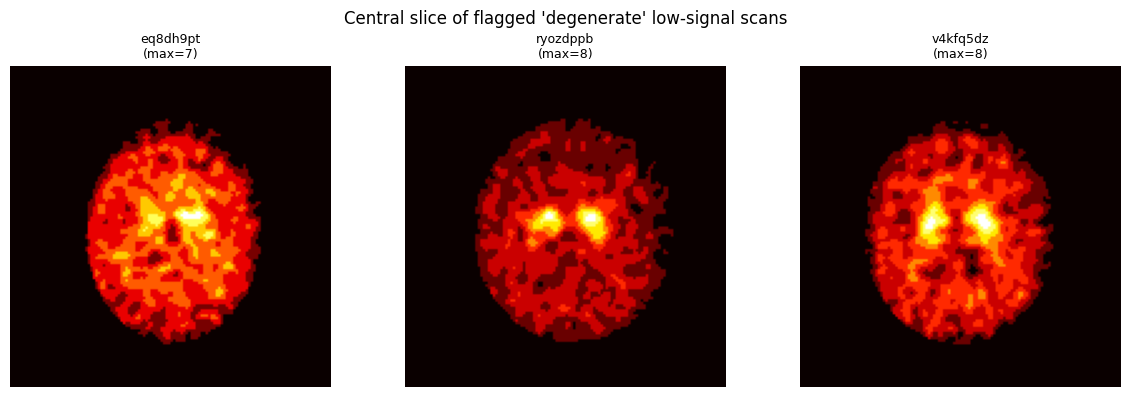

In [23]:
# --- Visual sanity check: are the "degenerate" low-signal scans blank/corrupted, or just very-low-count? ---
check_uids = degenerate["uid"].head(3).tolist()
fig, axes = plt.subplots(1, len(check_uids), figsize=(4 * len(check_uids), 4))
for ax, uid in zip(axes, check_uids):
    vol, _ = load_volume(uid)
    z = vol.shape[2] // 2
    ax.imshow(vol[:, :, z].T, cmap="hot", origin="lower")
    ax.set_title(f"{uid}\n(max={vol.max():.0f})", fontsize=9)
    ax.axis("off")
plt.suptitle("Central slice of flagged 'degenerate' low-signal scans")
plt.tight_layout()
plt.show()

### Findings from this addendum

- **The metadata-signature "duplicate" check was a false alarm** — confirmed by a real pixel-content hash check on the largest ambiguous group (460 volumes, all identical 256×256×256 @ 2.46mm): **zero true content collisions**. Lesson: file size is not a valid duplicate signature for uncompressed NIfTI; a genuine leakage/duplicate audit on this dataset would need real content hashing, and when done, finds no duplicates in the group checked.
- **The scale-regime split is only mildly associated with label** (low-magnitude regime: 61.0% abnormal vs. high-magnitude regime: 52.7% abnormal) — a real but modest ~8pt difference, not large enough to fully explain the ~2× median `intensity_max` gap (255 vs. 117) found earlier. So that median difference is likely *partly* genuine signal and partly regime composition — worth revisiting after proper normalization rather than trusting either number in isolation now.
- **The 25 "degenerate" low-signal scans are real anatomy, not corrupted/blank data** — visual check of 3 examples (max intensity 5-9) clearly shows normal bilateral striatal-uptake patterns once auto-scaled for display. This means the dataset spans **at least three distinct intensity-magnitude regimes** (ultra-low ~5-10, low ~100-1000, high ~10,000-65,000), all clinically valid — reinforcing, once again, that per-volume percentile-based normalization (not a fixed threshold) is the correct fix, and ruling out "just drop the low-signal ones as corrupted" as a shortcut.